In [1]:
from pathlib import Path
import sys
import warnings
import matplotlib.pyplot as plt
import optuna
import pandas as pd
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

warnings.filterwarnings("ignore")
print("All imports loaded successfully!")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

All imports loaded successfully!
device: cpu | torch 2.14.1+cpu


In [2]:
BASE_DIR = Path("..").resolve()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

PROCESSED_DIR = BASE_DIR / "data" / "cv" / "processed"
TRAIN_DIR = PROCESSED_DIR / "train_v2"
VAL_DIR = PROCESSED_DIR / "val_v2"
TEST_DIR = PROCESSED_DIR / "test_v2"
FRAMES_DIR = (
    PROCESSED_DIR / "frames_effnet"
)  
LABELS_CSV = BASE_DIR / "data" / "cv" / "raw" / "solution.csv"
OUTPUTS_DIR = BASE_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

for p in [TRAIN_DIR, VAL_DIR, TEST_DIR, LABELS_CSV]:
    print(p, "OK" if p.exists() else "!!! Does not exist")

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ldf = pd.read_csv(LABELS_CSV, dtype={"id": str})
group_map = dict(zip(ldf["id"].str.zfill(5), ldf["group"]))

C:\Users\98936\Desktop\incident-sentiment-analyzer\data\cv\processed\train_v2 OK
C:\Users\98936\Desktop\incident-sentiment-analyzer\data\cv\processed\val_v2 OK
C:\Users\98936\Desktop\incident-sentiment-analyzer\data\cv\processed\test_v2 OK
C:\Users\98936\Desktop\incident-sentiment-analyzer\data\cv\raw\solution.csv OK


In [10]:
N_FRAMES = 10  # Extract 10 images from each video

def extract_frames(video_path, out_dir, n=N_FRAMES):
    # If the images have already been extracted, do not reprocess
    if out_dir.exists() and any(out_dir.glob("*.jpg")):
        return True
    out_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))  # Open the video
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  # Total number of frames
    if total <= 0:
        cap.release()
        return False

    # 10 evenly spaced indices from the beginning to the end of the video
    for i, idx in enumerate(np.linspace(0, total - 1, n).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))  # Jump to this frame
        ok, frame = cap.read()  # Read the frame
        if ok:
            cv2.imwrite(str(out_dir / f"frame_{i:03d}.jpg"), frame)  # Save the frame
    cap.release()
    return True


failed = []
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for cls in ["negative", "positive"]:
        for video in sorted((split_dir / cls).glob("*.mp4")):
            ok = extract_frames(video, FRAMES_DIR / video.stem.zfill(5))
            if not ok:
                failed.append(video.name)

print("Failed videos:", len(failed), failed[:5])
print("Created directories:", len(list(FRAMES_DIR.iterdir())))

Failed videos: 0 []
Created directories: 150


In [11]:
def list_videos(split_dir):
    """List of (id, label) based on the file name and the folder name."""
    out = []
    for cls, label in [("negative", 0.0), ("positive", 1.0)]:
        for f in sorted((split_dir / cls).glob("*.mp4")):
            out.append((f.stem.zfill(5), label))
    return out


class CrashDataset(Dataset):
    def __init__(self, videos, frames_dir, transform=None):
        self.transform = transform
        self.samples = []
        for vid, label in videos:
            for p in sorted((frames_dir / vid).glob("*.jpg")):
                self.samples.append((p, label, vid))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, target, vid = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(target, dtype=torch.float32), vid


norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    norm,
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    norm,
])

train_videos = list_videos(TRAIN_DIR)
val_videos = list_videos(VAL_DIR)
test_videos = list_videos(TEST_DIR)

# Leakage check: all three numbers must be zero
ids = [{v for v, _ in vs} for vs in (train_videos, val_videos, test_videos)]
print("train∩val:", len(ids[0] & ids[1]),
      "train∩test:", len(ids[0] & ids[2]),
      "val∩test:", len(ids[1] & ids[2]))

train_dataset = CrashDataset(train_videos, FRAMES_DIR, train_transform)
val_dataset = CrashDataset(val_videos, FRAMES_DIR, val_transform)
test_dataset = CrashDataset(test_videos, FRAMES_DIR, val_transform)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

for n, ds in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    print(f"{n}: {len(ds)} frames, {len({s[2] for s in ds.samples})} videos")


train∩val: 0 train∩test: 0 val∩test: 0
train: 1050 frames, 105 videos
val: 220 frames, 22 videos
test: 230 frames, 23 videos


In [12]:
from src.cv.engine import build_model

test_model = build_model(dropout=0.2, device=device, backbone="efficientnet_b0")
print(test_model.classifier)
del test_model

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1, bias=True)
)


In [ ]:
from src.cv.engine import train_run

def objective(trial):
    params = {
        "backbone": "efficientnet_b0",
        "lr": trial.suggest_float("lr", 1e-4, 5e-3, log=True),
        "dropout": trial.suggest_float("dropout", 0.1, 0.5),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
        "optimizer": trial.suggest_categorical("optimizer", ["Adam", "AdamW"]),
    }
    epochs = trial.suggest_int("epochs", 4, 15)
    criterion = nn.BCEWithLogitsLoss()

    _, _, best_score, _ = train_run(
        params=params,
        epochs=epochs,
        train_dataset=train_dataset,
        val_loader=val_loader,
        criterion=criterion,
        device=device,
        trial=trial,
        patience=4,
        label_smoothing=0.1,
        metric="map",
        group_map=group_map,
    )
    return best_score


# Sanity check: group_map must not be empty
print("group_map sample:", list(group_map.items())[:5])

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2),
)

N_TRIALS = 3   # smoke test; after it works, it is going to change
print(f"Starting Optuna HPO for EfficientNet-B0 ({N_TRIALS} trials)...")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print("\nTrials:")
for t in study.trials:
    print(f"  #{t.number}  state={t.state.name}  value={t.value}")

print("\nBest trial:")
print(f"  Value (Val mAP): {study.best_value:.4f}")
for k, v in study.best_params.items():
    print(f"    {k}: {v}")


group_map sample: [('00204', 0), ('00030', 0), ('00146', 0), ('00020', 0), ('00511', 0)]
Starting Optuna HPO for EfficientNet-B0 (3 trials)...


Best trial: 0. Best value: 0.674436: 100%|██████████| 3/3 [18:07<00:00, 362.51s/it]


Trials:
  #0  state=COMPLETE  value=0.6744355325695038
  #1  state=COMPLETE  value=0.6543862999745351
  #2  state=COMPLETE  value=0.6160350946236113

Best trial:
  Value (Val mAP): 0.6744
    lr: 0.00043284502212938834
    dropout: 0.4802857225639665
    weight_decay: 0.001570297088405539
    batch_size: 16
    optimizer: Adam
    epochs: 14


In [14]:
from src.cv.engine import train_run

def objective(trial):
    params = {
        "backbone": "efficientnet_b0",
        "lr": trial.suggest_float("lr", 1e-4, 5e-3, log=True),
        "dropout": trial.suggest_float("dropout", 0.1, 0.5),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
        "optimizer": trial.suggest_categorical("optimizer", ["Adam", "AdamW"]),
    }
    epochs = trial.suggest_int("epochs", 4, 15)
    criterion = nn.BCEWithLogitsLoss()

    _, _, best_score, _ = train_run(
        params=params,
        epochs=epochs,
        train_dataset=train_dataset,
        val_loader=val_loader,
        criterion=criterion,
        device=device,
        trial=trial,
        patience=4,
        label_smoothing=0.1,
        metric="map",
        group_map=group_map,
    )
    return best_score

# Sanity check: group_map must not be empty
print("group_map sample:", list(group_map.items())[:5])

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2),
)

N_TRIALS =12 
print(f"Starting Optuna HPO for EfficientNet-B0 ({N_TRIALS} trials)...")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print("\nTrials:")
for t in study.trials:
    print(f"  #{t.number}  state={t.state.name}  value={t.value}")

print("\nBest trial:")
print(f"  Value (Val mAP): {study.best_value:.4f}")
for k, v in study.best_params.items():
    print(f"    {k}: {v}")

group_map sample: [('00204', 0), ('00030', 0), ('00146', 0), ('00020', 0), ('00511', 0)]
Starting Optuna HPO for EfficientNet-B0 (12 trials)...


Best trial: 9. Best value: 0.796477: 100%|██████████| 12/12 [32:59<00:00, 164.99s/it] 


Trials:
  #0  state=COMPLETE  value=0.7097319347319347
  #1  state=COMPLETE  value=0.7322852586010481
  #2  state=COMPLETE  value=0.6662723593134514
  #3  state=PRUNED  value=0.59992784992785
  #4  state=PRUNED  value=0.5711677211677211
  #5  state=COMPLETE  value=0.6878968253968254
  #6  state=PRUNED  value=0.591668714529677
  #7  state=COMPLETE  value=0.6839006952643316
  #8  state=PRUNED  value=0.5753707077236487
  #9  state=COMPLETE  value=0.7964770078406442
  #10  state=COMPLETE  value=0.7086940836940837
  #11  state=PRUNED  value=0.6300238836124001

Best trial:
  Value (Val mAP): 0.7965
    lr: 0.00010218376758008094
    dropout: 0.42618457138193366
    weight_decay: 0.001319994226153501
    batch_size: 32
    optimizer: AdamW
    epochs: 5


In [18]:
best_params = study.best_params.copy()
best_epochs = best_params.pop("epochs", 10)
best_params["backbone"] = "efficientnet_b0"

print(f"Training final model for {best_epochs} epochs...")
criterion = nn.BCEWithLogitsLoss()

model_efficientnet, history, best_val_score, best_state = train_run(
    params=best_params,
    epochs=best_epochs,
    train_dataset=train_dataset,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    trial=None,
    patience=4,
    label_smoothing=0.1,
    metric="map",
    group_map=group_map,
)

model_path = OUTPUTS_DIR / "efficientnet_b0_tuned.pth"
torch.save(best_state, model_path)
print(f"Saved: {model_path}")
print(f"Best Validation mAP: {best_val_score:.4f}")


Training final model for 5 epochs...
Saved: C:\Users\98936\Desktop\incident-sentiment-analyzer\outputs\efficientnet_b0_tuned.pth
Best Validation mAP: 0.5133


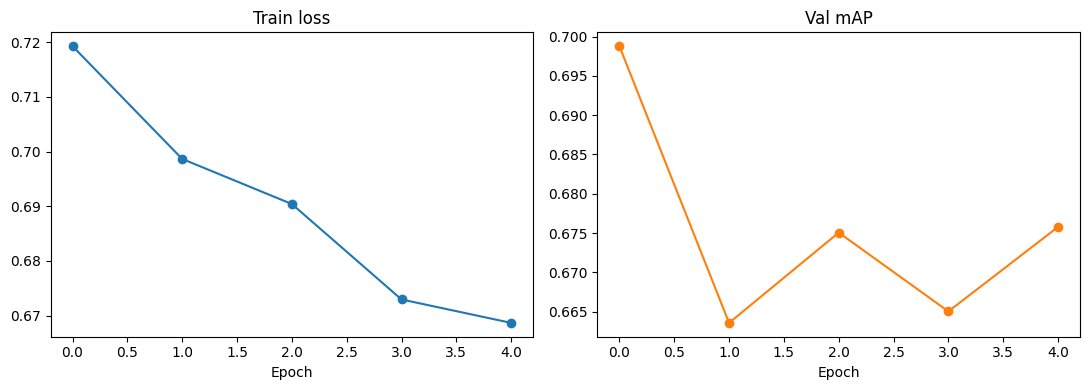

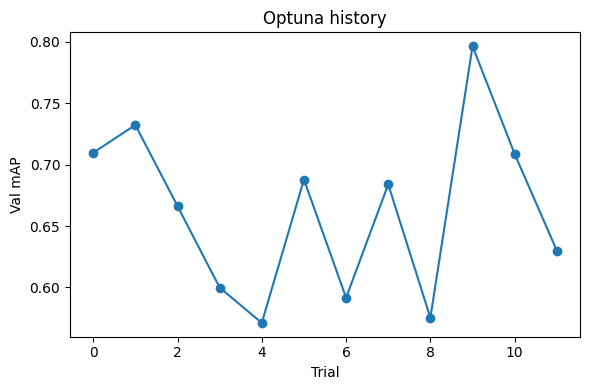

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], marker="o")
ax[0].set_title("Train loss")
ax[0].set_xlabel("Epoch")
ax[1].plot(history["val_score"], marker="o", color="tab:orange")
ax[1].set_title("Val mAP")
ax[1].set_xlabel("Epoch")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "efficientnet_training_curves.png", dpi=150)
plt.show()

trials = [t for t in study.trials if t.value is not None]
plt.figure(figsize=(6, 4))
plt.plot([t.number for t in trials], [t.value for t in trials], "o-")
plt.xlabel("Trial")
plt.ylabel("Val mAP")
plt.title("Optuna history")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "efficientnet_optuna_history.png", dpi=150)
plt.show()